In [1]:
import pandas as pd   
import numpy as np    
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

import seaborn as sns
import matplotlib.pyplot as plt


### 데이터 불러오기

In [2]:
df = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submission = pd.read_csv("submission_example.csv")

### 데이터 설명

| 변수명           | 데이터타입 | 설명                        | 범주 값 또는 예시                                                                                                                         |
| ------------- | ----- | ------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **age**       | 수치형   | 나이                        | -                                                                                                                                  |
| **job**       | 범주형   | 직업                        | admin, unknown, unemployed, management, housemaid, entrepreneur, student, blue-collar, self-employed, retired, technician, service |
| **marital**   | 범주형   | 결혼상태                      | married, divorced,single (사별해도 divorced로 포함)                                                                                                          |
| **education** | 범주형   | 학력                        | unknown, secondary, primary, tertiary                                                                                              |
| **default**   | 범주형   | 신용 채무 불이행 여부              | yes, no                                                                                                                            |
| **balance**   | 수치형   | 연평균 잔액 (단위: 유로)           | -                                                                                                                                  |
| **housing**   | 범주형   | 주택 대출 여부                  | yes, no                                                                                                                            |
| **loan**      | 범주형   | 개인 대출 여부                  | yes, no                                                                                                                            |
| **contact**   | 범주형   | 최근 연락 수단                  | unknown, telephone, cellular                                                                                                       |
| **day**       | 수치형   | 최근 연락 날짜                  | 1 \~ 31                                                                                                                            |
| **month**     | 범주형   | 최근 연락한 달                  | jan, feb, mar, ..., dec                                                                                                            |
| **duration**  | 수치형   | 최근 통화 시간 (초)              | -                                                                                                                                  |
| **campaign**  | 수치형   | 이번 캠페인 중 고객에게 연락한 횟수      | -                                                                                                                                  |
| **pdays**     | 수치형   | 이전 캠페인 이후 경과일 (-1은 연락 없음) | -                                                                                                                                  |
| **previous**  | 수치형   | 이전 캠페인에서 고객에게 연락한 횟수      | -                                                                                                                                  |
| **poutcome**  | 범주형   | 이전 캠페인 결과                 | unknown, other, failure, success                                                                                                   |
| **label**     | 범주형   | 정기예금 가입 여부 (타겟 변수)        | 1 = 가입, 0 = 미가입                                                                                                                    |


## EDA

### 결측치 확인

In [3]:
df.isnull().sum()

ID           0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
label        0
dtype: int64

#### Target

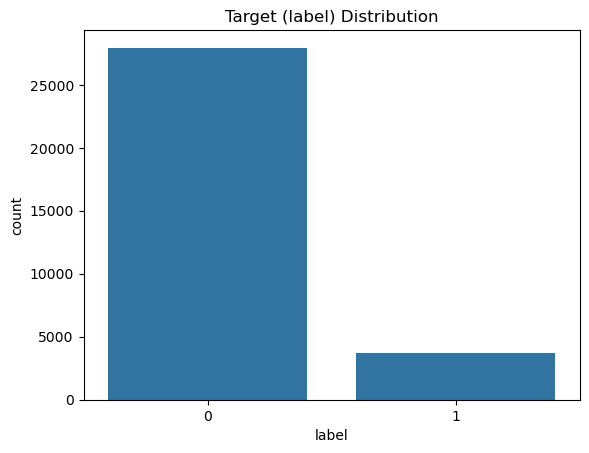

label
0    0.883022
1    0.116978
Name: proportion, dtype: float64


In [4]:
sns.countplot(data=df, x='label')
plt.title("Target (label) Distribution")
plt.show()

print(df['label'].value_counts(normalize=True))


### 범주형 변수

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/2361515881.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = df[col].value_counts().values, y= df[col].value_counts().index,  palette="pastel")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/2361515881.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = df[col].value_counts().values, y= df[col].value_counts().index,  palette="pastel")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/2361515881.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  s

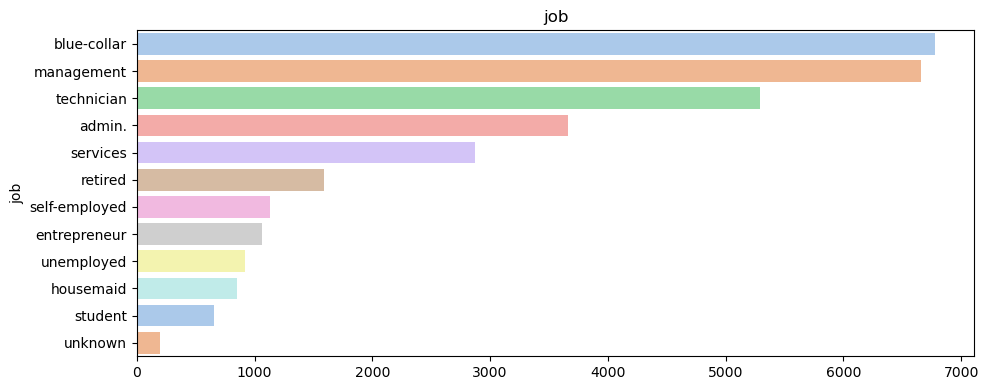

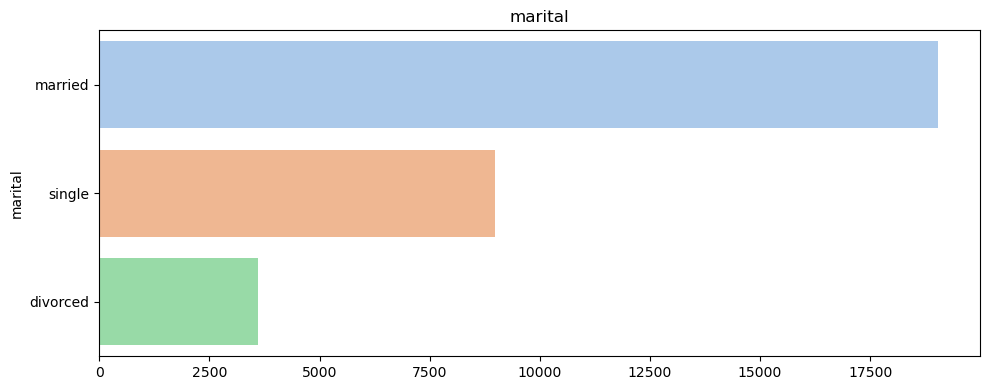

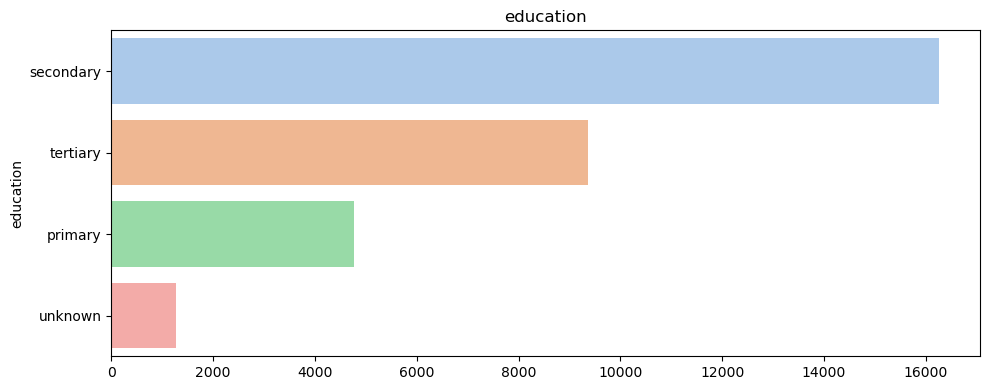

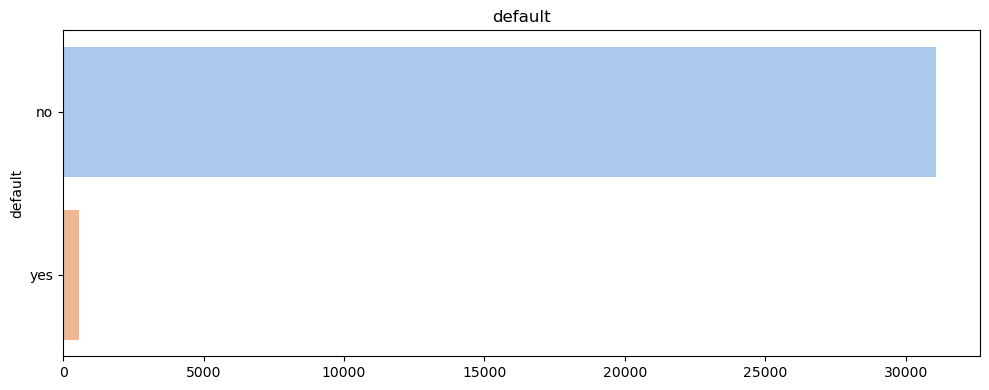

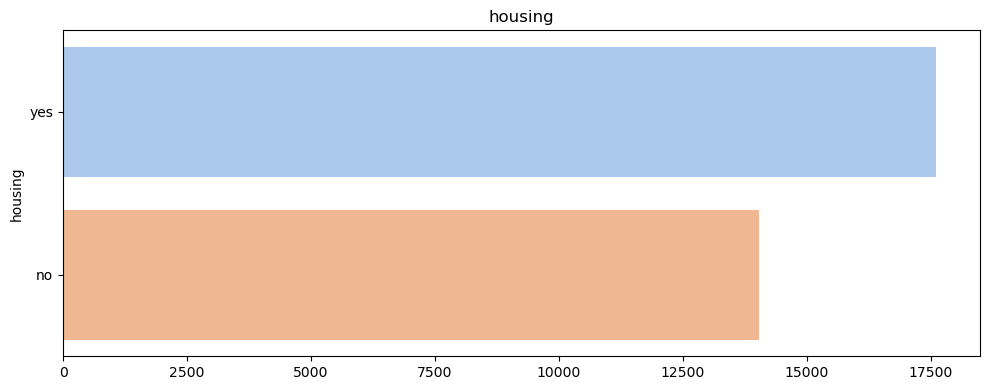

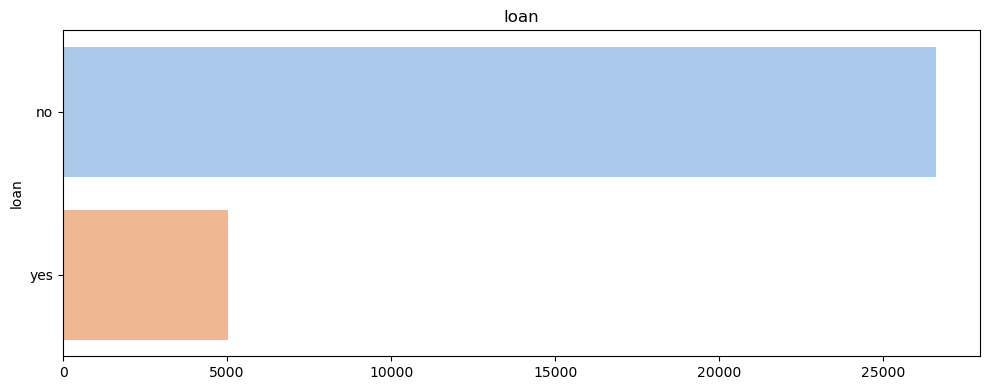

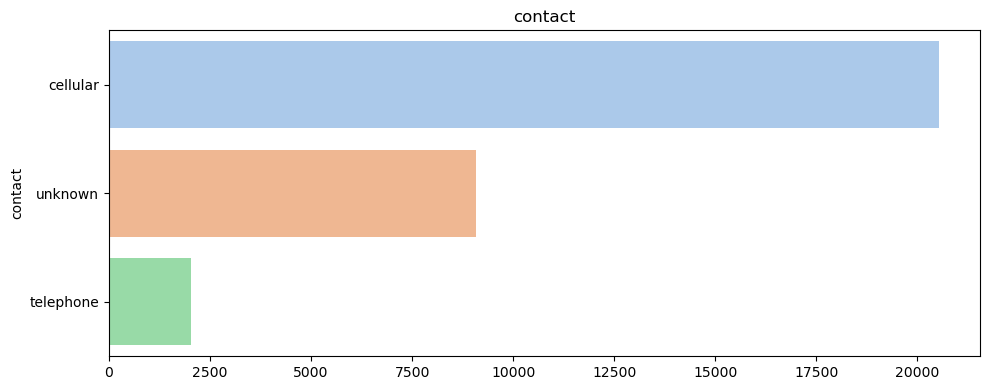

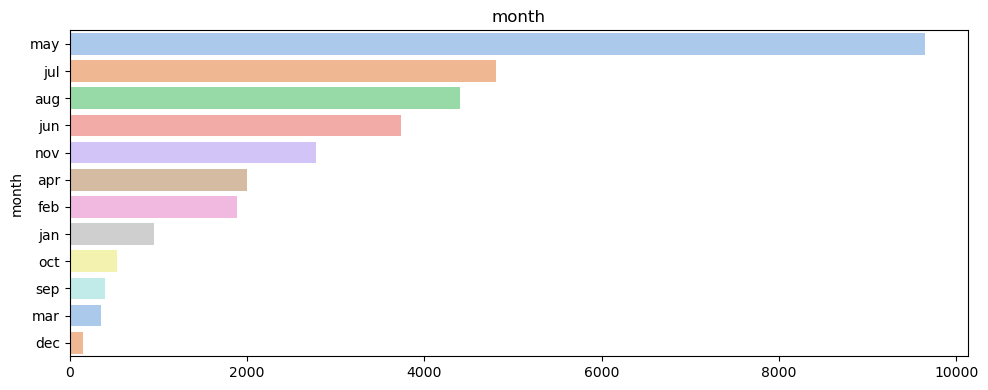

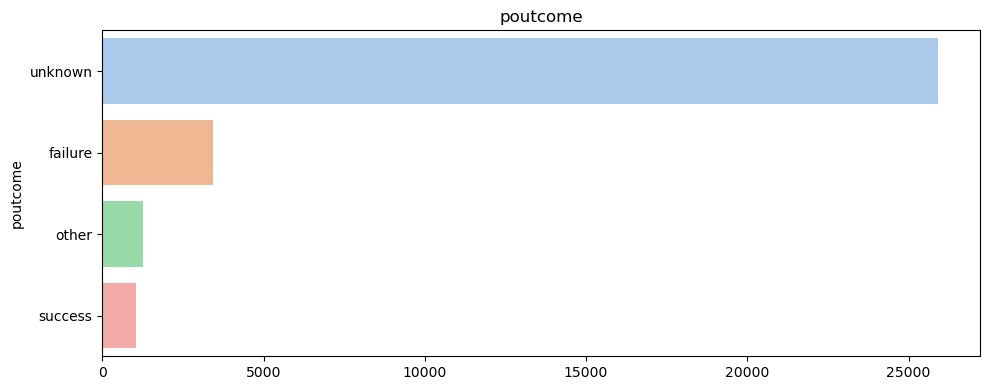

In [5]:
cat_col = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

for col in cat_col:
    plt.figure(figsize=(10,4))
    sns.barplot(x = df[col].value_counts().values, y= df[col].value_counts().index,  palette="pastel")
    plt.title(col)
    plt.tight_layout()


#### 범주형 변수 label에 따른 빈도차이

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

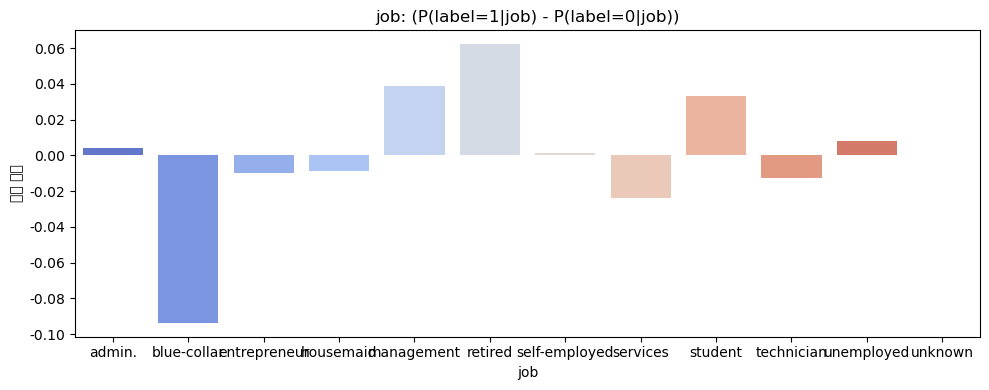

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

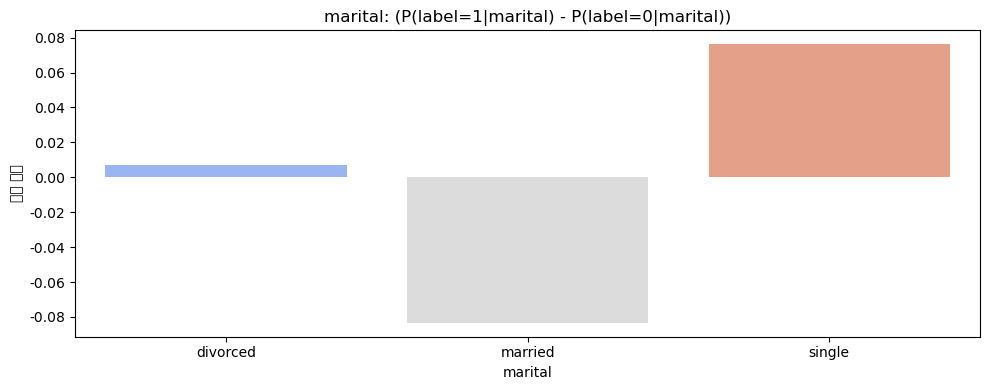

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

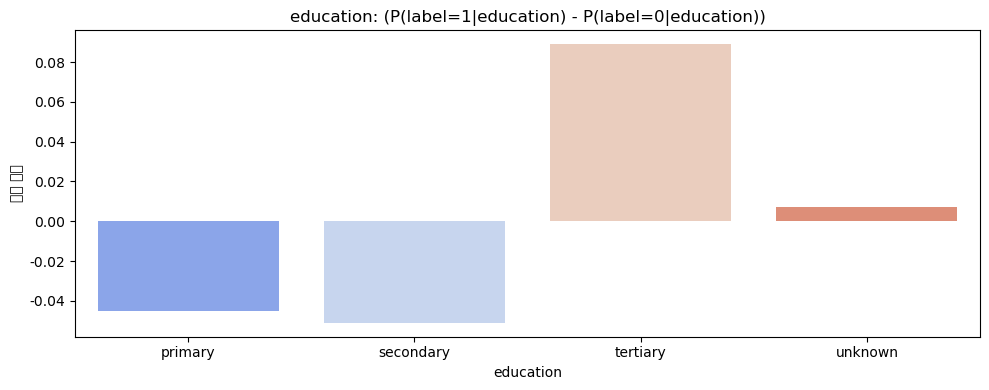

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

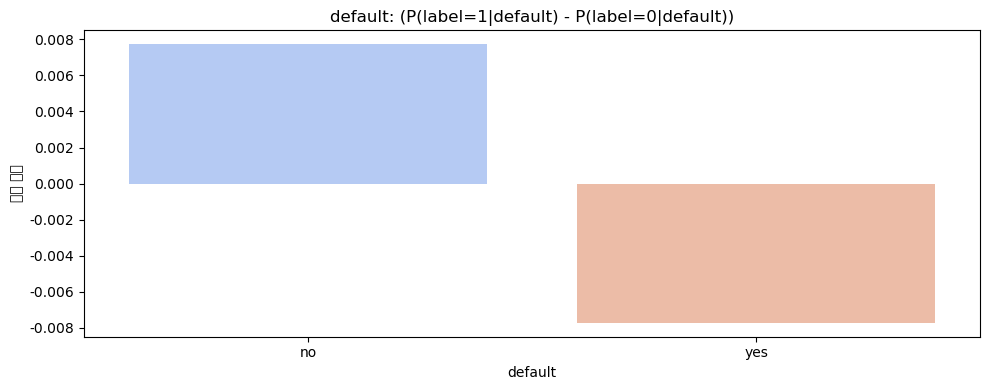

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

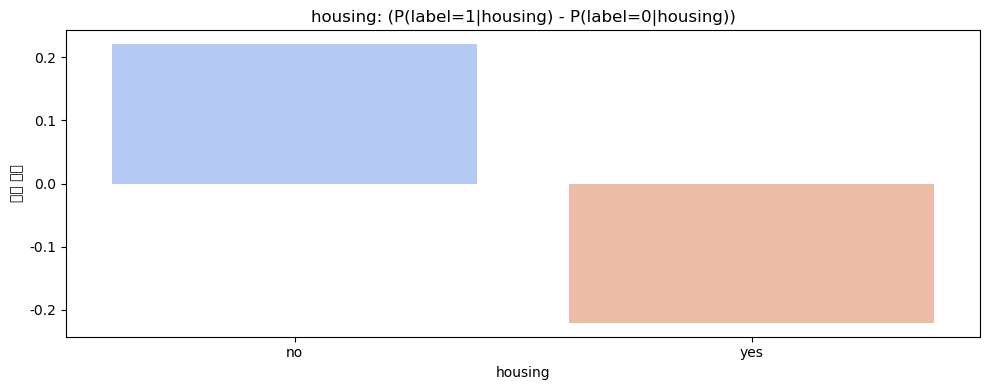

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

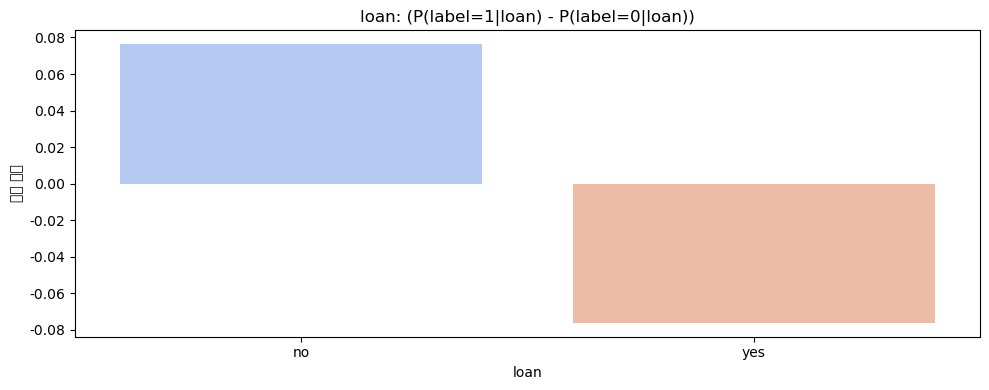

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

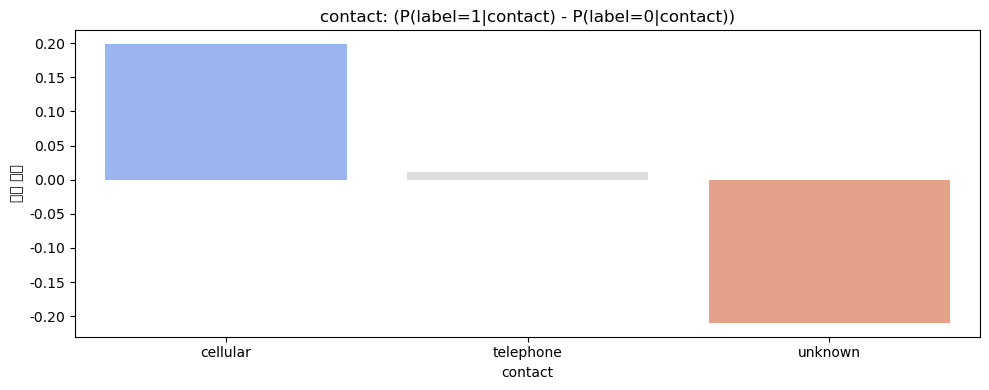

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

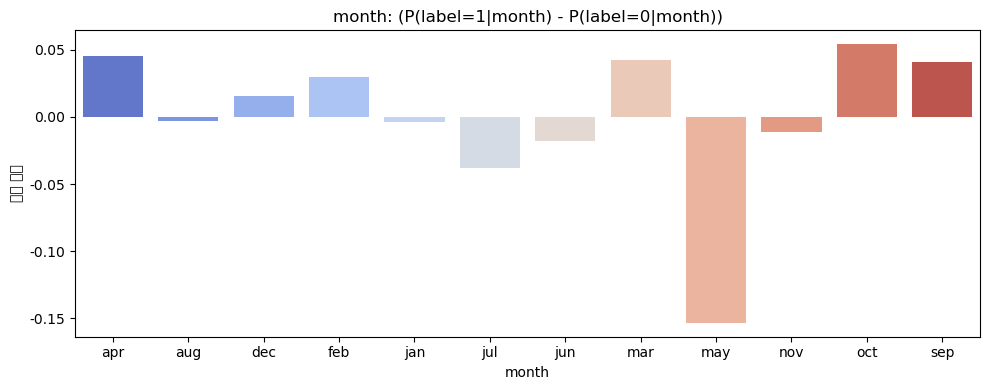

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3071797227.py:29: UserWarning: Glyph 51060 (\N{HA

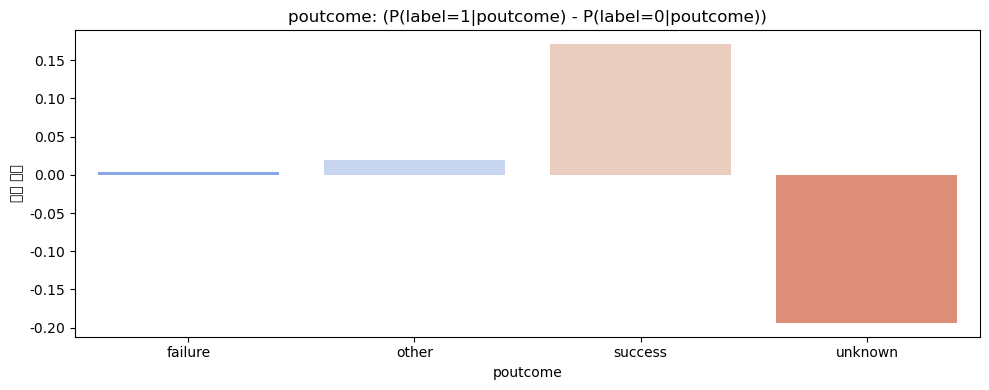

In [6]:
#각 범주별로 label에 따른 빈도 차이를 barplot으로 보기

plt.rcParams['axes.unicode_minus'] = False #마이너스 부호 깨짐 현상 해결용

for col in cat_col:
    plt.figure(figsize=(10,4))
    # 각 label별 count
    pos_counts = df.loc[df['label'] == 1, col].value_counts()
    neg_counts = df.loc[df['label'] == 0, col].value_counts()
    
    # 모든 카테고리 index
    all_index = sorted(set(pos_counts.index).union(set(neg_counts.index)))
    
    # 전체 positive/negative 개수
    freq_pos = (df['label'] == 1).sum()
    freq_neg = (df['label'] == 0).sum()
    
    # 비율 차이 계산
    diff = [
        pos_counts.get(k, 0) / freq_pos - neg_counts.get(k, 0) / freq_neg
        for k in all_index
    ]
    
    # barplot (x=카테고리, y=비율 차이)
    sns.barplot(x=all_index, y=diff, palette="coolwarm")
    plt.title(f"{col}: (P(label=1|{col}) - P(label=0|{col}))")
    plt.xlabel(col)
    plt.ylabel("비율 차이")
    plt.tight_layout()
    plt.show()


- 범주형 비율 해석

    - job
        - student, retired, unemployed : 양수 -> 가입자 비중이 더 높음
        - blue-collar, services : 음수 -> 마케팅 효율이 낮은 직업에 해당

    - education
        - tertiary  > 양수에 해당하므로 고학력자일 수록 정기예금에 관심이 많다는 것을 해석할 수 있음
    
    - contact
        - cellular : 휴대폰에 해당하는데 이로 연락을 했을 때 가입할 확률이 올라감
    
    - month
        - mar apr, oct, sep : 양수 
        - may : significantly : 음수

    - martial
        - single : 양수 
            -> 독신일 경우 독립적이기에 가입가능성이 올라가는 것으로 해석 가능
        
        - married : 음수 

    - poutcome 
        - success : 이전 캠페인시 성공시 가입확률 올라감
        - unknown : 과거 기록이 없을 때는 음수일 경우가 많기에 주의

    - default, loan, housing
        - 신용 불이행 X, 대출이 없을 수록 가입확률이 높아짐


In [1]:
#통화시간 EDA

In [ ]:
min_duration = df['duration'].min()
max_duration = df['duration'].max()
median_duration = df['duration'].mean()
standard_dev_duration = df["duration"].std()

print("Min call duration: ", min_duration)
print("Max call duration: ", max_duration)
print("Median call duration: ", round(median_duration, 2))
print("Standard diveation in call duration: ", round(standard_dev_duration, 2))

Min call duration:  0
Max call duration:  3881
Median call duration:  258.09
Standard diveation in call duration:  255.74


In [ ]:
first_quartile = df['duration'].quantile(q = 0.25)
second_quartile = df['duration'].quantile(q = 0.50)
third_quartile = df['duration'].quantile(q = 0.75)
fourth_quartile = df['duration'].quantile(q = 1)
IRQ = third_quartile - second_quartile

print("Second Quartile: ", second_quartile)
print("Third Quartile: ", third_quartile)
print("Inter quartile range(range within which most data is present): ",IRQ)

Second Quartile:  180.0
Third Quartile:  320.0
Inter quartile range(range within which most data is present):  140.0


Text(0.5, 1.0, 'Count of contacts made in each month')

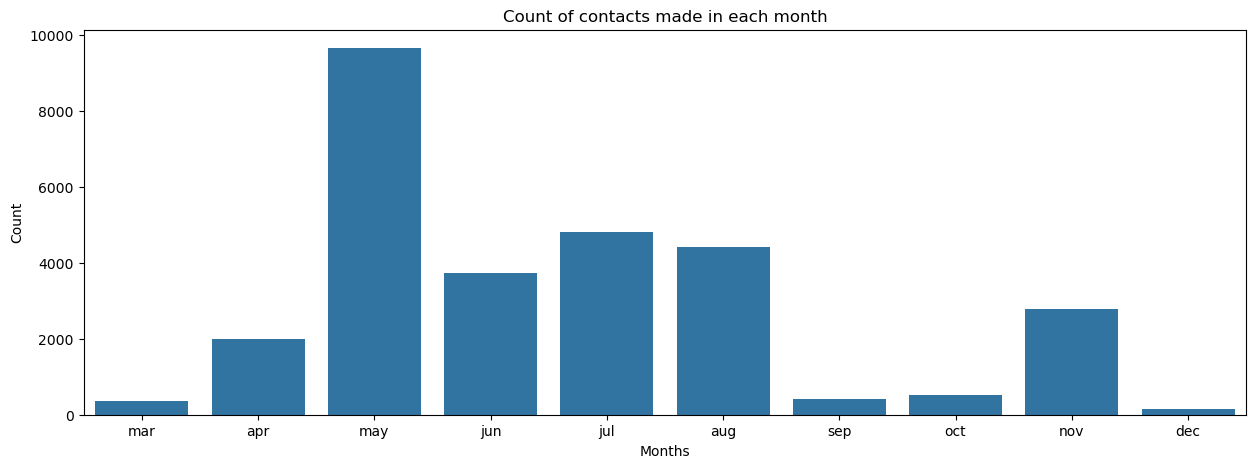

In [ ]:
# For Months
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(x = 'month', data = df, order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])
ax.set_xlabel("Months")
ax.set_ylabel("Count")
ax.set_title("Count of contacts made in each month")

Text(0.5, 1.0, 'log(Duration) vs Jobs')

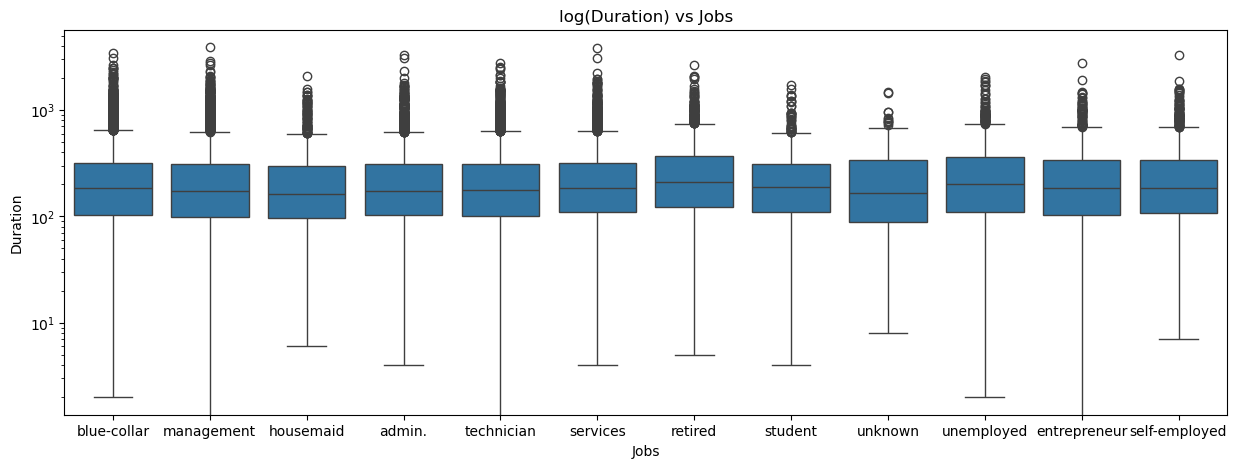

In [ ]:
#job duration
fig, ax = plt.subplots(figsize = (15, 5))
sns.boxplot(x = "job", y = "duration", data = df, orient = 'v')
ax.set_xlabel("Jobs")
ax.set_ylabel("Duration")
ax.set_yscale("log")
ax.set_title("log(Duration) vs Jobs")

Text(0.5, 1.0, 'log(Duration) vs Education')

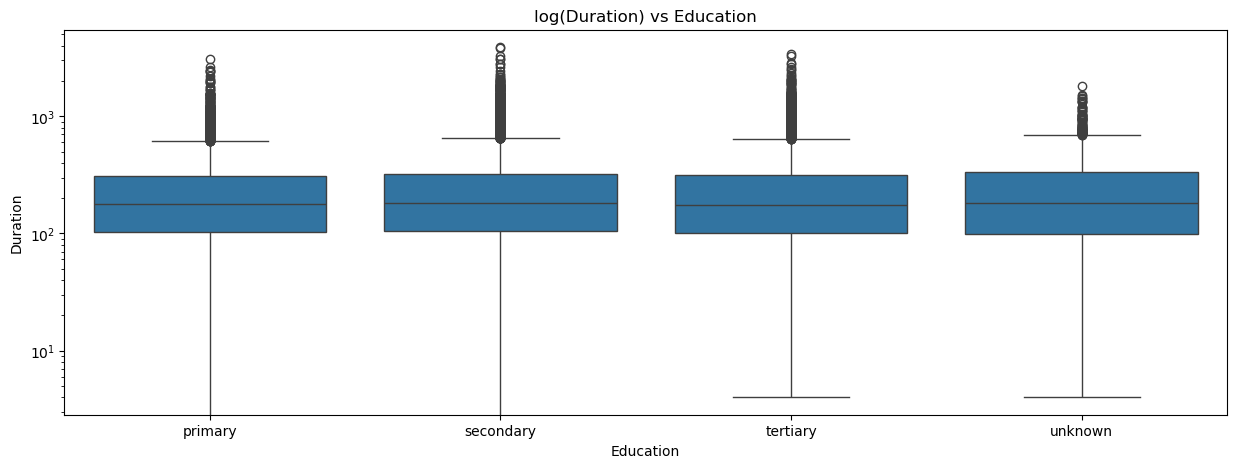

In [ ]:
fig, ax = plt.subplots(figsize = (15, 5))
sns.boxplot(x = "education", y = "duration", data = df, orient = 'v')
ax.set_xlabel("Education")
ax.set_ylabel("Duration")
ax.set_yscale("log")
ax.set_title("log(Duration) vs Education")

## 수치형 변수

In [7]:
num_col = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

In [8]:
df[num_col].describe()

,age,balance,day,duration,campaign,pdays,previous
count,31647.000000,31647.000000,31647.000000,31647.000000,31647.000000,31647.000000,31647.000000
mean,40.916833,1370.050084,15.818277,258.088824,2.752615,40.023604,0.575062
std,10.621773,3122.054996,8.315467,255.737568,3.080952,100.154518,2.433034
min,18.000000,-4057.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,73.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,451.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1418.500000,21.000000,320.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,3881.000000,63.000000,854.000000,275.000000


### OUTLIER

In [9]:

def check_num_ouliers(df):
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']:
            q1 = df[col].quantile(0.25)
            q3 = df[col].quantile(0.75)
            iqr = q3 - q1
            lower_bound = q1 - 1.5 * iqr
            upper_bound = q3 + 1.5 * iqr
            outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
            if not outliers.empty:
                print(f' {col}의 이상치 개수 : {len(outliers)}')
check_num_ouliers(df)

 age의 이상치 개수 : 337
 balance의 이상치 개수 : 3327
 duration의 이상치 개수 : 2242
 campaign의 이상치 개수 : 2134
 pdays의 이상치 개수 : 5733
 previous의 이상치 개수 : 5733
 label의 이상치 개수 : 3702


### 수치형 변수별 분포 확인

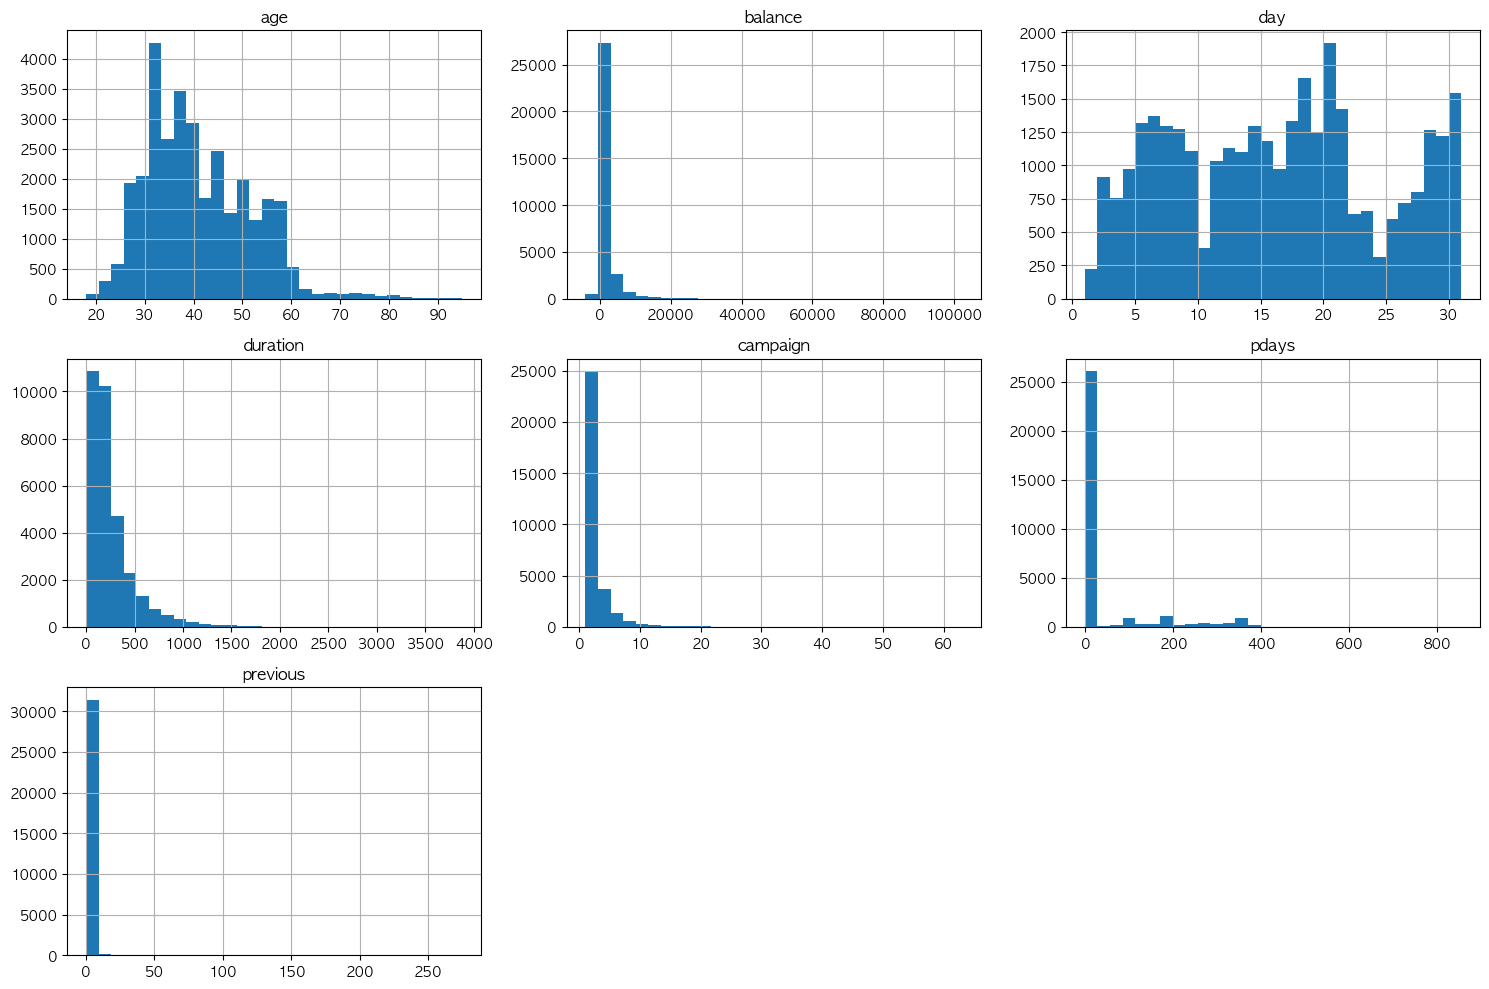

In [10]:
plt.rcParams['font.family'] = 'AppleGothic' #mac 폰트 코드

df[num_col].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

### train_test data 나누기

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['label' , 'ID'])  
y = df['label']               

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## PipeLine

#### 범주형 변수 pipeline 작성

- one hot encoder : binary 변수 일때 사용
    - 'default', 'loan', 'housing' (Y/N) , 'marital', 'contact' (유의미한 most_frequent에 해당하는 범주가 있음)
- target encder : 범주와 타겟간의 연관성이 명확할 때 사용
    - job, poutcome,
- ordinal encoder : 순서 있는 범주에 사용
    - education

In [12]:
#!pip install category_encoders 

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import FunctionTransformer
import numpy as np

# 월 -> 숫자 변환
month_map = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
             'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}

# custom function for mapping
def month_to_num(X):
    return X.replace(month_map)

month_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('mapper', FunctionTransformer(month_to_num)),
])

education_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        categories=[['primary', 'secondary', 'tertiary']],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

job_target_encoder = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target', TargetEncoder())
])

poutcome_target_encoder = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target', TargetEncoder())
])

binary_col = ['default', 'loan', 'housing']
binary_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'))
])

other_col = ['marital', 'contact']
other_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer
from sklearn.compose import ColumnTransformer

#pdays 에 대해서는 -1 (연락없음)과 같은 특수 카테고리기 때문에 -1 변수를 999로 할당함.
pdays_transformer = Pipeline([
    ('minus1_to_nan', FunctionTransformer(lambda x: x.replace(-1, np.nan))),
    ('imputer', SimpleImputer(strategy='constant', fill_value=999)),
    ('scaler', PowerTransformer(method='yeo-johnson'))
])

num_pipeline = ColumnTransformer(transformers=[
    ('age', StandardScaler(), ['age']),
    ('balance', PowerTransformer(method='yeo-johnson'), ['balance']),
    ('duration', PowerTransformer(method='yeo-johnson'), ['duration']),
    ('campaign', RobustScaler(), ['campaign']),
    ('previous', PowerTransformer(method='yeo-johnson'), ['previous']),
    ('pdays', pdays_transformer, ['pdays'])
], remainder='drop')

In [15]:
cat_preprocessor = ColumnTransformer(transformers=[
    ('month', month_transformer, ['month']),
    ('education', education_transformer, ['education']),
    ('job', job_target_encoder, ['job']),
    ('poutcome', poutcome_target_encoder, ['poutcome']),
    ('binary', binary_transformer, binary_col),
    ('other', other_transformer, other_col)
])


In [16]:
model_pipeline = ColumnTransformer(transformers=[
    ('cat', cat_preprocessor, cat_col),
    ('num', num_pipeline, [col for col in num_col if col != 'day']) #day 변수 제외
])

model_pipeline.set_output(transform='pandas')

ColumnTransformer(transformers=[('cat',
                                 ColumnTransformer(transformers=[('month',
                                                                  Pipeline(steps=[('imputer',
                                                                                   SimpleImputer(strategy='most_frequent')),
                                                                                  ('mapper',
                                                                                   FunctionTransformer(func=<function month_to_num at 0x17f728360>))]),
                                                                  ['month']),
                                                                 ('education',
                                                                  Pipeline(steps=[('imputer',
                                                                                   SimpleImputer(strategy='most_frequent')),
                                                                                  ('ordinal',
                                                                                   OrdinalEncoder(categorie...
                                                                 ('campaign',
                                                                  RobustScaler(),
                                                                  ['campaign']),
                                                                 ('previous',
                                                                  PowerTransformer(),
                                                                  ['previous']),
                                                                 ('pdays',
                                                                  Pipeline(steps=[('minus1_to_nan',
                                                                                   FunctionTransformer(func=<function <lambda> at 0x30930f560>)),
                                                                                  ('imputer',
                                                                                   SimpleImputer(fill_value=999,
                                                                                                 strategy='constant')),
                                                                                  ('scaler',
                                                                                   PowerTransformer())]),
                                                                  ['pdays'])]),
                                 ['age', 'balance', 'duration', 'campaign',
                                  'pdays', 'previous'])])

In [17]:
model_pipeline.fit(X_train, y_train) #target_encoding 때문에 y_train 필요로 함
X_train_pipe = model_pipeline.transform(X_train)
X_val_pipe = model_pipeline.transform(X_val)

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explici

## Modeling

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
import xgboost as xgb
import lightgbm as lgb

In [19]:
models = {
    "RandomForest": RandomForestClassifier(random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(probability=True),
    "XGBoost": xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": lgb.LGBMClassifier(random_state=42)
}

In [20]:
from sklearn.metrics import f1_score

results = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', model_pipeline),
        ('classifier', model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)
    f1 = f1_score(y_val, y_pred)
    results[name] = f1

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explici

[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000833 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 751
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116996 -> initscore=-2.021185
[LightGBM] [Info] Start training from score -2.021185


/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)


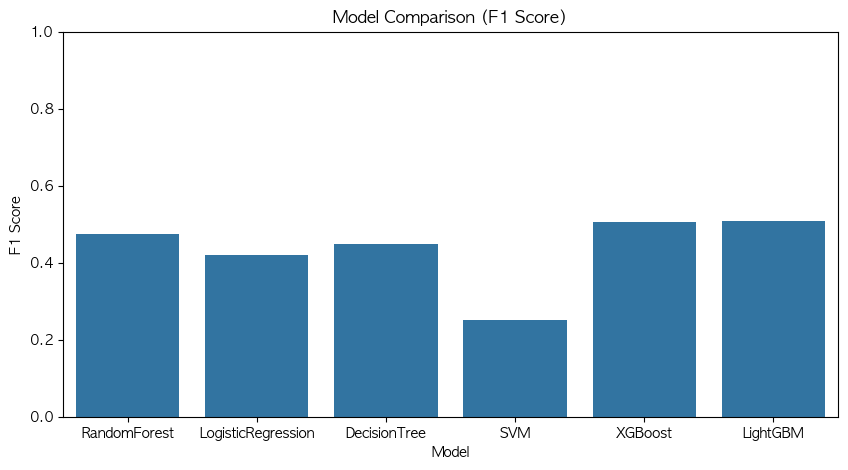

In [21]:
result_df = pd.DataFrame(list(results.items()), columns=['Model', 'F1 Score'])
plt.figure(figsize=(10,5))
sns.barplot(x='Model', y='F1 Score', data=result_df)
plt.title('Model Comparison (F1 Score)')
plt.ylim(0, 1)
plt.show()

### Optuna

In [22]:
# optimizing 10 번 진행

- RandomForest, XGBoost, LogisticRegression 하이퍼파라미터 튜닝
- StackingClassifier로 세 모델 앙상블 구성
- predict_proba()로 확률값 추출
- Threshold를 0.3 ~ 0.7 사이에서 변화시켜 F1-score를 최적화
- 최적 threshold에서의 F1-score를 Optuna의 objective값으로 반환

In [23]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
import numpy as np
from sklearn.metrics import f1_score

In [25]:
def objective(trial):
    rf = RandomForestClassifier(
        n_estimators=trial.suggest_int("rf_n_estimators", 50, 200),
        max_depth=trial.suggest_int("rf_max_depth", 3, 15),
        class_weight="balanced",
        random_state=42
    )
    xgb = XGBClassifier(
        n_estimators=trial.suggest_int("xgb_n_estimators", 50, 200),
        max_depth=trial.suggest_int("xgb_max_depth", 3, 15),
        learning_rate=trial.suggest_float("xgb_lr", 0.01, 0.3),
        use_label_encoder=False,
        eval_metric="logloss",
        random_state=42,
        scale_pos_weight=trial.suggest_float("xgb_spw", 1.0, 5.0),
    )
    lr = LogisticRegression(
        C=trial.suggest_float("lr_C", 0.01, 10.0),
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )

    clf = StackingClassifier(
        estimators=[("rf", rf), ("xgb", xgb), ("lr", lr)],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5,
        passthrough=True  # 원본 특성도 최종 모델에 전달
    )

    clf.fit(X_train_pipe, y_train)
    probs = clf.predict_proba(X_val_pipe)[:, 1]

    # Threshold tuning
    thresholds = np.linspace(0.3, 0.7, 21)
    f1_scores = [f1_score(y_val, (probs >= t).astype(int)) for t in thresholds]
    
    return max(f1_scores)

import optuna

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print("Best F1-score:", study.best_value)
print("Best params:", study.best_params)

[I 2025-05-20 18:43:43,246] A new study created in memory with name: no-name-2eb20022-b69c-4cdb-8bd9-54d19285ca45
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:43:43] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:43:47] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:43:48] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWa

Best F1-score: 0.6004784688995215
Best params: {'rf_n_estimators': 142, 'rf_max_depth': 3, 'xgb_n_estimators': 96, 'xgb_max_depth': 3, 'xgb_lr': 0.2601060798286778, 'xgb_spw': 3.6692956639657517, 'lr_C': 0.13109887684072988}


In [28]:
best_params = study.best_params

final_rf = RandomForestClassifier(
    n_estimators=best_params["rf_n_estimators"],
    max_depth=best_params["rf_max_depth"],
    class_weight="balanced",
    random_state=42
)
final_xgb = XGBClassifier(
    n_estimators=best_params["xgb_n_estimators"],
    max_depth=best_params["xgb_max_depth"],
    learning_rate=best_params["xgb_lr"],
    scale_pos_weight=best_params["xgb_spw"],
    use_label_encoder=False,
    eval_metric="logloss",
    random_state=42
)
final_lr = LogisticRegression(
    C=best_params["lr_C"],
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

final_stack = StackingClassifier(
    estimators=[("rf", final_rf), ("xgb", final_xgb), ("lr", final_lr)],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    passthrough=True
)

final_stack.fit(X_train_pipe, y_train)

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:45:43] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:45:46] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:45:46] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:45:46] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encode

StackingClassifier(cv=5,
                   estimators=[('rf',
                                RandomForestClassifier(class_weight='balanced',
                                                       max_depth=3,
                                                       n_estimators=142,
                                                       random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False,
                                              eval_metric='loglo...
                                              max_delta_step=None, max_depth=3,
                                              max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=96, n_jobs=None,
                                              num_parallel_tree=None, ...)),
                               ('lr',
                                LogisticRegression(C=0.13109887684072988,
                                                   class_weight='balanced',
                                                   max_iter=1000,
                                                   random_state=42))],
                   final_estimator=LogisticRegression(max_iter=1000),
                   passthrough=True)

In [31]:
# Threshold 다시 튜닝해서 적용
final_probs = final_stack.predict_proba(X_val_pipe)[:, 1]
thresholds = np.linspace(0.3, 0.7, 21)
f1s = [f1_score(y_val, (final_probs >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmax(f1s)]
print(f"Best threshold: {best_threshold:.2f}, F1: {np.max(f1s):.4f}")

Best threshold: 0.30, F1: 0.6005


### 최종 test 데이터에 적용

In [33]:
test_pipe = model_pipeline.transform(test)

test_probs = final_stack.predict_proba(test_pipe)[:, 1]

test_pred = (test_probs >= best_threshold).astype(int)


/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_68829/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)


## Submission

In [34]:
submission = pd.DataFrame({
    "ID": test["ID"],        # ID 컬럼이 있다면
    "label": test_pred
})
submission.to_csv("submission_try01.csv", index=False)